In [1]:
import os
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib import cm
from matplotlib.colors import Normalize
from mpl_toolkits.axes_grid1 import make_axes_locatable
from mpl_toolkits.axes_grid1.anchored_artists import AnchoredSizeBar
import matplotlib.font_manager as fm
import json
import numpy as np
from matplotlib.colors import LinearSegmentedColormap, ListedColormap

custom_seq = ListedColormap(["white", "blue","teal",  "gray", "black"])

In [2]:
toppath = '/mnt/SSD/fische_r/COELY'

In [3]:
sample = '4'
ts = 32

In [4]:
x = 675
y = 277
z = 573+600

xcrop = 50
xcrop2 = 821-30

zcrop = 500
zcrop2 = 1700


ycrop = 50
ycrop2 = 350

In [5]:
def pad_cropping(crops, xcrop, xcrop2, ycrop, ycrop2, zcrop, zcrop2):
    dx = xcrop2 - xcrop
    dy = ycrop2 - ycrop
    dz = zcrop2 - zcrop

    x1 = xcrop - crops[0]
    y1 = ycrop - crops[2]
    z1 = zcrop - crops[4]

    x2 = x1 + dx
    y2 = y1 + dy
    z2 = z1 + dz

    return x1, x2, y1, y2, z1, z2

In [6]:
lowpath = os.path.join(toppath, '04_lowpass_filtered_4D', '04_'+sample+'_lowpass_filteres_4D.nc')
lowdata = xr.open_dataset(lowpath)

In [7]:
cropping = lowdata.attrs['post rotation cropping coordinates [a:b,c:d,e:f]']

In [8]:
training_path =  '/mnt/SSD/fische_r/COELY/05_water_GDL_ML/'
jsonpath = os.path.join(training_path, 'cathode_cropping_and_aligning.json')
crop_dict = json.load(open(jsonpath, 'r'))

(a,b,c,d) = crop_dict[sample]
(e,f) = (50,-50)

# Registration

In [33]:
regpath = os.path.join('/mpc/homes/fische_r/nanotom_data/misc/Processing_workflow/', '02_4_registered_3p1D.nc')

In [38]:
regdata = xr.open_dataset(regpath)
images = [im for im in regdata.keys() if im[3:7] == 'imag']
images.sort()
im = regdata[images[ts]]

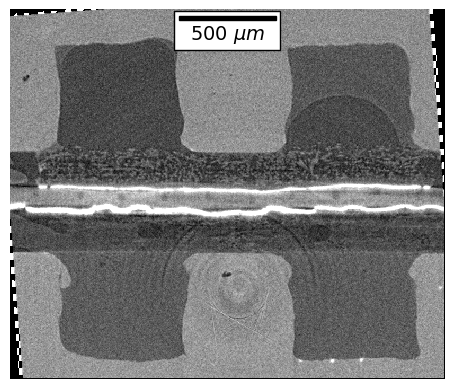

In [39]:
im2 = im.sel(z = z-crops[4]).data
im2bu = im2.copy()
im2 = im2bu#[xc1:xc2,yc1:yc2]
im2 = im2.transpose(1,0)
im3 = im2.copy()

fig, ax = plt.subplots()
ax.imshow(im2, cmap='gray', interpolation = 'none', vmin=10000, vmax=15000)
ax.axis('off')
scalebar = AnchoredSizeBar(ax.transData,
                       500/2.75, '500 $\mu m$', 'upper center', 
                       pad=0.25,
                       color='black',
                       frameon=True,
                       size_vertical=8,
                       fontproperties=fm.FontProperties(size=14))
ax.add_artist(scalebar)

# Lowpass filter

In [22]:
imlow = lowdata['image_data'][...,ts]

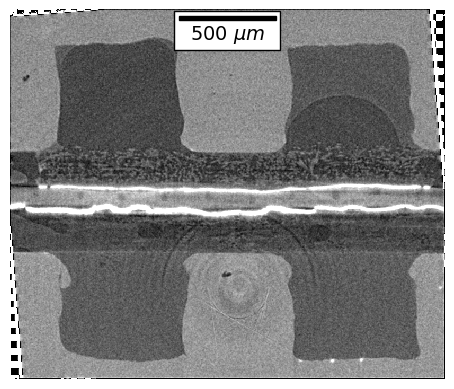

In [32]:
crops = segdata.attrs['05_ML_cropping']
xc1, xc2, yc1, yc2, zc1, zc2 = pad_cropping(segdata.attrs['05_ML_cropping'], xcrop, xcrop2, ycrop, ycrop2, zcrop, zcrop2)

im2 = imlow.sel(z = z-crops[4]).data
im2bu = im2.copy()
im2 = im2bu#[xc1:xc2,yc1:yc2]
im2 = im2.transpose(1,0)
im3 = im2.copy()

fig, ax = plt.subplots()
ax.imshow(im2, cmap='gray', interpolation = 'none', vmin=10000, vmax=15000)
ax.axis('off')
scalebar = AnchoredSizeBar(ax.transData,
                       500/2.75, '500 $\mu m$', 'upper center', 
                       pad=0.25,
                       color='black',
                       frameon=True,
                       size_vertical=8,
                       fontproperties=fm.FontProperties(size=14))
ax.add_artist(scalebar)

# ML segmentation

In [9]:
def change_image_colors(im):
    #0 fiber, 1 air, 2 water, 3 solids, 4 slug water -> 0 - air, 1 - slug wate, 2 water, 3 solid, 4 fiber
    new_im = np.zeros(im.shape, dtype=np.uint8)
    new_im[im==0] = 4
    new_im[im==2] = 1
    new_im[im==4] = 2
    new_im[im==3] = 3
    return new_im
    

In [10]:
segpath = os.path.join(toppath, '05_water_GDL_ML', sample, sample+'water_segmentation.nc')
segdata = xr.open_dataset(segpath)
imseg1 = segdata['segmented'][...,ts]
imseg2 = segdata['segmented_filtered'][...,ts]

In [11]:
segdata.attrs['05_ML_cropping']

array([ 40, 790,  40, 380,  50, -50])

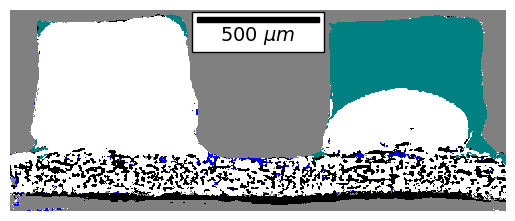

In [26]:
crops = segdata.attrs['05_ML_cropping']
xc1, xc2, yc1, yc2, zc1, zc2 = pad_cropping(segdata.attrs['05_ML_cropping'], xcrop, xcrop2, ycrop, ycrop2, zcrop, zcrop2)

im2 = imseg1.sel(z = z-crops[4]).data
im2bu = im2.copy()
im2 = im2bu[xc1:xc2,yc1:yc2]
im2 = im2.transpose(1,0)

fig, ax = plt.subplots()
ax.imshow(change_image_colors(im2), cmap=custom_seq,vmin=0, vmax=4, interpolation = 'none')
ax.axis('off')
scalebar = AnchoredSizeBar(ax.transData,
                       500/2.75, '500 $\mu m$', 'upper center', 
                       pad=0.25,
                       color='black',
                       frameon=True,
                       size_vertical=8,
                       fontproperties=fm.FontProperties(size=14))
ax.add_artist(scalebar)

In [27]:
im2.shape

(300, 740)

In [28]:
im3.shape

(340, 750)

# Filter segmentation

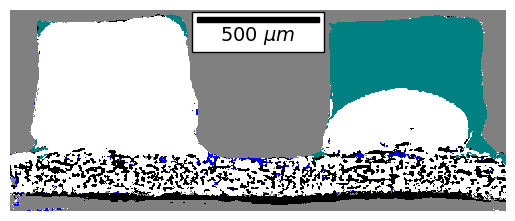

In [15]:
crops = segdata.attrs['05_ML_cropping']
xc1, xc2, yc1, yc2, zc1, zc2 = pad_cropping(segdata.attrs['05_ML_cropping'], xcrop, xcrop2, ycrop, ycrop2, zcrop, zcrop2)

im2 = imseg2.sel(z = z-crops[4]).data
im2bu = im2.copy()
im2 = im2bu[xc1:xc2,yc1:yc2]
im2 = im2.transpose(1,0)

fig, ax = plt.subplots()
ax.imshow(change_image_colors(im2), cmap=custom_seq,vmin=0, vmax=4, interpolation = 'none')
ax.axis('off')
scalebar = AnchoredSizeBar(ax.transData,
                       500/2.75, '500 $\mu m$', 'upper center', 
                       pad=0.25,
                       color='black',
                       frameon=True,
                       size_vertical=8,
                       fontproperties=fm.FontProperties(size=14))
ax.add_artist(scalebar)

# ROI segmentation

In [17]:
ROIpath = os.path.join(toppath, '05_water_GDL_ML', sample, sample+'_ROI_segments.nc')
ROIdata = xr.open_dataset(ROIpath)
imROI = ROIdata['ROI'][...,ts]

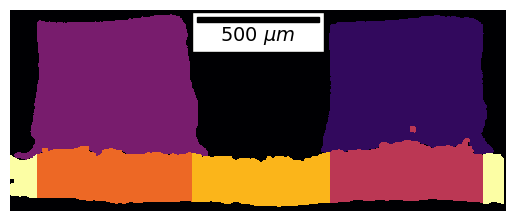

In [19]:
crops = segdata.attrs['05_ML_cropping']
xc1, xc2, yc1, yc2, zc1, zc2 = pad_cropping(segdata.attrs['05_ML_cropping'], xcrop, xcrop2, ycrop, ycrop2, zcrop, zcrop2)

im2 = imROI.sel(z = z-crops[4]).data
im2bu = im2.copy()
im2 = im2bu[xc1:xc2,yc1:yc2]
im2 = im2.transpose(1,0)

fig, ax = plt.subplots()
ax.imshow(im2, cmap='inferno',  interpolation = 'none')
ax.axis('off')
scalebar = AnchoredSizeBar(ax.transData,
                       500/2.75, '500 $\mu m$', 'upper center', 
                       pad=0.25,
                       color='black',
                       frameon=True,
                       size_vertical=8,
                       fontproperties=fm.FontProperties(size=14))
ax.add_artist(scalebar)